# Quickstart: NOAA RTMA, RTMA-RU and URMA analyses, virtual - dynamical.org Icechunk Zarr

[NOAA's RTMA family](https://emc.ncep.noaa.gov/emc/pages/numerical_forecast_systems/rtma.php) combines observations with a model background to estimate near-surface weather. These virtual archives cover CONUS on a 2.5 km grid. RTMA and its Rapid Update sibling emphasize timely situational awareness; URMA waits for more observations and serves as NOAA's analysis of record for forecast verification and calibration.

| Product | Analysis cadence | NOAA upstream timing | Virtual archive starts | Availability here |
| --- | --- | --- | --- | --- |
| RTMA | Hourly | About 55 minutes after valid time | 2017-05-02 | Available in staging; executed below |
| RTMA-RU | Every 15 minutes | About 15–20 minutes after valid time | 2017-12-13 (planned) | Launch pending |
| URMA | Hourly | Runs six hours later to include late observations; delivery follows processing | 2017-05-02 (planned); wave height from 2018-12-03 12:00 UTC | Launch pending |

These timing descriptions come from [NOAA's system overview](https://emc.ncep.noaa.gov/emc/pages/numerical_forecast_systems/rtma.php), not a delivery guarantee for these archives. All three apply observation quality control. URMA's later observation cutoff supports retrospective verification; it does not make every grid cell independent truth.

Only hourly RTMA is available in the selected catalog today. RU and URMA have launch sections below; their examples will be added and executed when those products launch. The dates above describe these virtual archives, not the first dates NOAA operated each system. Precipitation is not included in these virtual products.

Dataset documentation:
- RTMA: https://rtma-analysis-staging.dynamical-org.pages.dev/catalog/noaa-rtma-analysis-virtual/

In [ ]:
# If running locally, follow README.md for simple dependency installation.
# If using Google Colab, run this cell.
!uv pip install dynamical-catalog cartopy rioxarray pyproj matplotlib

In [2]:
import os

# Remove the staging override when the family notebook is promoted to production.
os.environ.setdefault(
    "DYNAMICAL_STAC_CATALOG_URL", "https://stac-staging.dynamical.org/catalog.json"
)

import dynamical_catalog

## RTMA: hourly situational awareness

Open the hourly analysis, then extract a point time series and a regional map. The native grid has projected `x` and `y` coordinates; transform longitude/latitude for point selection and use the stored CRS for geographic subsets.

In [3]:
rtma = dynamical_catalog.open("noaa-rtma-analysis-virtual", chunks=None)
rtma

<xarray.Dataset> Size: 32TB
Dimensions:                       (time: 83019, y: 1597, x: 2345)
Coordinates:
  * time                          (time) datetime64[ns] 664kB 2017-05-02 ... ...
  * y                             (y) float64 13kB 3.79e+06 ... -2.638e+05
  * x                             (x) float64 19kB -3.271e+06 ... 2.682e+06
    latitude                      (y, x) float32 15MB ...
    longitude                     (y, x) float32 15MB ...
    spatial_ref                   int64 8B ...
Data variables: (12/13)
    cloud_ceiling_height          (time, y, x) float64 2TB ...
    dew_point_temperature_2m      (time, y, x) float64 2TB ...
    geopotential_height_surface   (time, y, x) float64 2TB ...
    pressure_surface              (time, y, x) float64 2TB ...
    specific_humidity_2m          (time, y, x) float64 2TB ...
    temperature_2m                (time, y, x) float64 2TB ...
    ...                            ...
    wind_gust_10m                 (time, y, x) float64 2TB ...
    visibility_surface            (time, y, x) float64 2TB ...
    total_cloud_cover_atmosphere  (time, y, x) float64 2TB ...
    wind_speed_10m                (time, y, x) float64 2TB ...
    wind_v_10m                    (time, y, x) float64 2TB ...
    wind_direction_10m            (time, y, x) float64 2TB ...
Attributes:
    dataset_id:          noaa-rtma-analysis-virtual
    dataset_version:     0.1.0
    name:                NOAA RTMA analysis, virtual
    description:         Hourly Real-Time Mesoscale Analysis (RTMA) operated ...
    attribution:         NOAA NWS NCEP RTMA data processed by dynamical.org f...
    license:             CC-BY-4.0
    spatial_domain:      Continental United States
    spatial_resolution:  2.5 km
    time_domain:         2017-05-02 00:00:00 UTC to Present
    time_resolution:     1 hour

The Pacific Northwest experienced [record heat in late June 2021](https://www.ncei.noaa.gov/news/national-climate-202106). Start with hourly temperature at the grid cell nearest Seattle; all times are UTC.

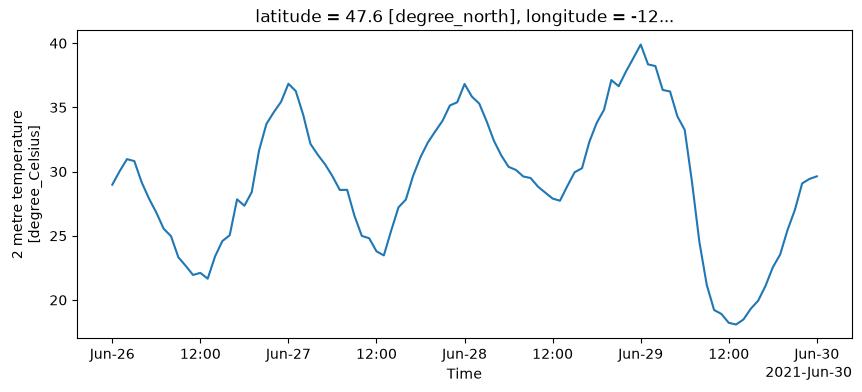

In [4]:
import rioxarray  # noqa: F401  enables the .rio accessor
from pyproj import Transformer

lon_lat_to_grid = Transformer.from_crs("EPSG:4326", rtma.rio.crs, always_xy=True)
seattle_x, seattle_y = lon_lat_to_grid.transform(-122.33, 47.61)

(
    rtma["temperature_2m"]
    .sel(time=slice("2021-06-26T00", "2021-06-30T00"))
    .sel(x=seattle_x, y=seattle_y, method="nearest")
    .plot(size=4, aspect=2.5)
)

Compare the point series with a regional temperature map at 23 UTC on 28 June (4 pm Pacific daylight time).

In [5]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt

grid = rtma.spatial_ref.attrs
rtma_proj = ccrs.LambertConformal(
    central_longitude=grid["longitude_of_central_meridian"],
    central_latitude=grid["latitude_of_projection_origin"],
    standard_parallels=grid["standard_parallel"],
    globe=ccrs.Globe(
        semimajor_axis=grid["semi_major_axis"],
        semiminor_axis=grid["semi_minor_axis"],
    ),
)

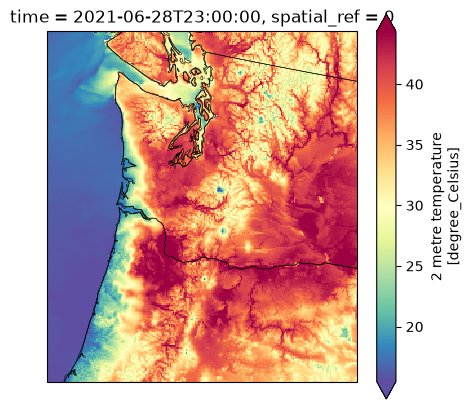

In [6]:
heat = (
    rtma["temperature_2m"]
    .sel(time="2021-06-28T23")
    .rio.clip_box(-125, 44, -119, 49, crs="EPSG:4326")
)

plot = heat.plot(
    subplot_kws={"projection": rtma_proj},
    transform=rtma_proj,
    cmap="Spectral_r",
    center=False,
    robust=True,
    size=5,
    aspect=1,
)
plot.axes.coastlines(resolution="50m", linewidth=0.5)
plot.axes.add_feature(cfeature.STATES, linewidth=0.4)

### Where were the strongest winds along the Front Range?

On 30 December 2021, [downslope winds fanned the Marshall Fire](https://www.weather.gov/bou/HighWinds12_30_2021). Map analyzed 10 m wind speed at 19 UTC (noon Mountain standard time); Superior locates the affected area.

`wind_u_10m` and `wind_v_10m` are grid-relative and require rotation before use as eastward/northward winds. Here we use scalar speed; `wind_direction_10m` is clockwise from true north, indicating where the wind comes from.

Text(-105.1, 39.95, 'Superior')

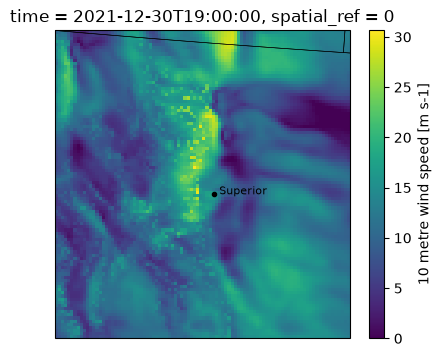

In [7]:
front_range = (
    rtma[["wind_speed_10m", "temperature_2m", "dew_point_temperature_2m"]]
    .sel(time="2021-12-30T19")
    .rio.clip_box(-106.5, 39, -104, 41, crs="EPSG:4326")
    .load()
)

plot = front_range.wind_speed_10m.plot(
    subplot_kws={"projection": rtma_proj},
    transform=rtma_proj,
    cmap="viridis",
    vmin=0,
    size=4,
    aspect=1.2,
)
plot.axes.add_feature(cfeature.STATES, linewidth=0.4)
plot.axes.plot(-105.15, 39.95, "ko", markersize=3, transform=ccrs.PlateCarree())
plot.axes.text(-105.10, 39.95, "Superior", transform=ccrs.PlateCarree(), fontsize=8)

### How dry was the near-surface air?

At the same time, compare the temperature–dewpoint spread across the foothills and plains. A larger spread indicates drier air; it does not measure fuel dryness or fire extent.

Text(-105.1, 39.95, 'Superior')

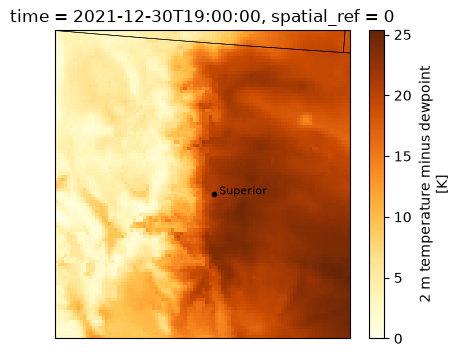

In [8]:
dewpoint_spread = front_range.temperature_2m - front_range.dew_point_temperature_2m
dewpoint_spread.attrs = {"long_name": "2 m temperature minus dewpoint", "units": "K"}

plot = dewpoint_spread.plot(
    subplot_kws={"projection": rtma_proj},
    transform=rtma_proj,
    cmap="YlOrBr",
    vmin=0,
    size=4,
    aspect=1.2,
)
plot.axes.add_feature(cfeature.STATES, linewidth=0.4)
plot.axes.plot(-105.15, 39.95, "ko", markersize=3, transform=ccrs.PlateCarree())
plot.axes.text(-105.10, 39.95, "Superior", transform=ccrs.PlateCarree(), fontsize=8)

### Animated map: how did cold air spread across Texas in February 2021?

An [Arctic outbreak brought cold air and winter weather to Texas in February 2021](https://www.weather.gov/fwd/Feb-2021-WinterEvent). Follow analyzed temperature from 14 February at 12 UTC to 15 February at 12 UTC, sampling every two hours and averaging 4 × 4 grid cells to keep the animation compact; the color scale stays fixed.

In [9]:
from IPython.display import HTML
from matplotlib.animation import FuncAnimation

cold = (
    rtma["temperature_2m"]
    .sel(time=slice("2021-02-14T12", "2021-02-15T12"))
    .isel(time=slice(None, None, 2))
    .rio.clip_box(-104, 26, -93, 36.5, crs="EPSG:4326")
    .coarsen(x=4, y=4, boundary="trim")
    .mean(keep_attrs=True)
    .load()
)

fig, ax = plt.subplots(
    figsize=(8, 6),
    dpi=72,
    subplot_kw={"projection": rtma_proj},
    constrained_layout=True,
)
image = cold.isel(time=0).plot(
    ax=ax,
    transform=rtma_proj,
    cmap="RdBu_r",
    vmin=-20,
    vmax=20,
)
ax.add_feature(cfeature.STATES, linewidth=0.4)
ax.coastlines(resolution="50m", linewidth=0.5)


def draw_frame(i: int) -> None:
    image.set_array(cold.isel(time=i).values.ravel())
    ax.set_title(str(cold.time.values[i])[:16] + " UTC")


anim = FuncAnimation(fig, draw_frame, frames=cold.sizes["time"], interval=450)
plt.close(fig)
HTML(anim.to_jshtml())

### Before using ceiling and visibility

`cloud_ceiling_height` (source CEIL) and `visibility_surface` (VIS) retain raw finite source values in metres, including clipped bounds: do not automatically replace them with missing values. Source bounds have changed over time. In NOAA's current RTMA code, the upper ceiling bound can also represent no-ceiling conditions. The archive does not assign a ceiling datum across its full history; consult the [validation report](https://dataset-validation-reports.dynamical.org/noaa-rtma-analysis-virtual/latest/validation_report.html) before interpreting ceiling heights, threshold counts, or trends. It also lists source archive gaps that appear as missing analyses.

## RTMA-RU: quarter-hour situational awareness — launch pending

RTMA-RU provides a new analysis every 15 minutes for weather changes that hourly snapshots can miss. It prioritizes low-latency situational awareness, including aviation use.

Examples will be added when `noaa-rtma-ru-analysis-virtual` launches.

## URMA: delayed analysis for verification — launch pending

URMA admits late observations unavailable to the faster RTMA run, making it useful for retrospective verification and calibration. This virtual product will also include significant wave height from the start date listed above.

Examples will be added when `noaa-urma-analysis-virtual` launches.

## Community challenge

- How does the timing of the June heat-wave peak differ between coastal and inland grid cells? For independent checks, use stations withheld from the analysis.
- Once RTMA-RU launches, which short wind events look different at 15-minute and hourly cadence?
- Once URMA launches, where do its later observations change RTMA's estimates most? The products share a model background; compare how the later observation cutoff changes the analysis rather than treating either product as independent truth.